# Wine Quality Classification: Support Vector Classifier with Hyperparameter Tuning

**Author:** Kwenev Stephen

## Overview

This project classifies Portuguese "Vinho Verde" wines as **lower quality** or **higher quality** from their chemical properties, using a Support Vector Classifier (SVC). It then uses grid search to tune the model's hyperparameters and checks whether tuning helps.

**What this notebook does**

1. Loads and inspects the wine quality data (6,497 red and white wines).
2. Turns the quality score into a binary label and prepares the features (missing values, standardisation, train-test split).
3. Trains a baseline SVC.
4. Defines a custom log-loss scoring function.
5. Uses 5-fold cross-validated grid search to tune `C` and `gamma`.
6. Compares the default and tuned models, including a sanity check against a naive baseline.

**Main finding:** both models reach about 96.4-96.5% accuracy, but so does a model that labels every wine "higher quality", because only about 4% of wines are low quality. Neither model is useful at spotting low-quality wine, and tuning changed only 2 predictions out of 1,625. The value of this project is in the workflow and in showing why accuracy alone can be misleading.

**Tools:** Python, pandas, NumPy, scikit-learn, matplotlib

## How to run

Install the requirements with `pip install -r requirements.txt`, then run the notebook from top to bottom. The data is read directly from the web, so an internet connection is needed.

## 1. The data

The data comes from the [Wine Quality dataset](https://archive.ics.uci.edu/ml/datasets/wine+quality) (UCI Machine Learning Repository), which covers red and white Portuguese "Vinho Verde" wines. Each row is one wine.

- **Features:** `type` (0 = white, 1 = red), fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol.
- **Target:** `quality`, a score from 0 to 10.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import preprocessing, metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.svm import SVC

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/Explore-AI/Public-Data/master/Data/classification_sprint/winequality.csv')
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 6497, Columns: 13


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,0,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,0,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,0,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,0,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
missing = df.isna().sum()
print("Missing values per column (only columns with any):")
print(missing[missing > 0])

Missing values per column (only columns with any):
fixed acidity       10
volatile acidity     8
citric acid          3
residual sugar       2
chlorides            2
pH                   9
sulphates            4
dtype: int64


A small number of values are missing in seven columns (2 to 10 each). The preprocessing step below fills them with zero.

Next, the distribution of the quality score. The next section splits it into "lower" and "higher" quality, so it is worth seeing how the scores are spread first.

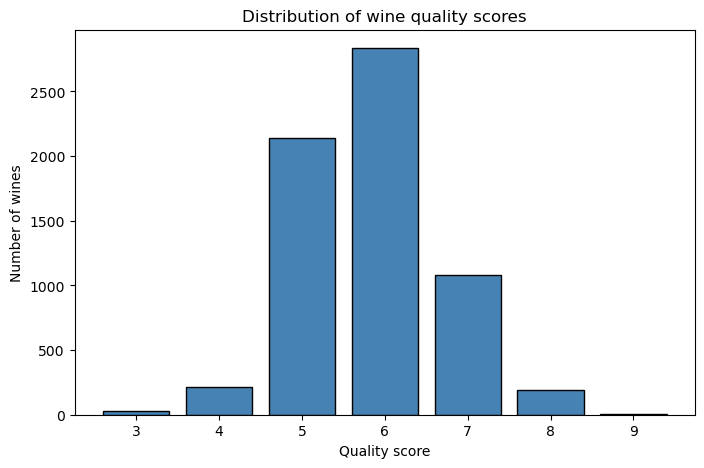

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

In [4]:
quality_counts = df['quality'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(quality_counts.index, quality_counts.values, color='steelblue', edgecolor='black')
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.title("Distribution of wine quality scores")
plt.show()

quality_counts

Most wines score 5, 6 or 7. Very few score 4 or below (246 of 6,497 wines, about 3.8%). This imbalance matters a lot later.

## 2. Data preprocessing

I turn this into a binary classification problem:

- Quality **4 or below** becomes `0` (lower quality).
- Quality **5 or above** becomes `1` (higher quality).

The function then:

- Fills missing values with zero.
- Standardises the features (mean 0, standard deviation 1) with `StandardScaler`, which matters for SVC because it is sensitive to feature scale.
- Splits the data 75% training and 25% testing, with `random_state=42` so the split is repeatable.

In [5]:
def data_preprocess(df):
    """
    Prepare the wine data for classification.

    Fills missing values with 0, converts quality to a binary label
    (1 if quality >= 5, else 0), standardises the features, and returns
    a 75/25 train-test split as ((X_train, y_train), (X_test, y_test)).
    """
    df = df.fillna(0)
    df['quality'] = df['quality'].apply(lambda x: 1 if x >= 5 else 0)
    y = df['quality'].values
    X = df.drop('quality', axis=1)
    X = preprocessing.StandardScaler().fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    return (X_train, y_train), (X_test, y_test)


(X_train, y_train), (X_test, y_test) = data_preprocess(df)

print(f"Training set: {X_train.shape[0]} wines | Test set: {X_test.shape[0]} wines")
print(f"Share of higher-quality wines in the test set: {y_test.mean():.4f}")

Training set: 4872 wines | Test set: 1625 wines
Share of higher-quality wines in the test set: 0.9643


**Two limitations of this step**

- **Scaling before splitting.** The scaler is fitted on all the data before the split, so the test set has influenced the scaling. This is a small form of data leakage. The proper approach is to fit the scaler on the training data only and then apply it to the test data. I kept the original order here; when I checked, doing it the proper way gave the same default-model accuracy on this data (0.9637).
- **Filling missing values with zero.** This is simple but not ideal, since zero is not a realistic value for measurements like pH. Only about 40 values are affected, so the impact is small, but median imputation would be a better choice.

## 3. Baseline model

I train an SVC with default settings (`gamma='auto'`, `random_state=40`) as the starting point.

In [6]:
def train_SVC_model(X_train, y_train):
    """Train and return a default SVC model."""
    model = SVC(random_state=40, gamma='auto')
    model.fit(X_train, y_train)
    return model


svc = train_SVC_model(X_train, y_train)
print("Classes:", svc.classes_)

Classes: [0 1]


## 4. Scoring with log loss

The task uses **log loss** as the scoring metric. It penalises predictions that are confidently wrong, and lower values are better:

$$H(p,q) = -\frac{1}{N}\sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i) \right]$$

Predictions are clipped to a tiny range (1e-15 to 1 - 1e-15) so the logarithm never receives exactly 0.

In [7]:
def custom_scoring_function(y_true, y_pred):
    """Calculate the log loss between true labels and predictions, rounded to 7 decimals."""
    epsilon = 1e-15
    y_pred = np.maximum(epsilon, y_pred)
    y_pred = np.minimum(1 - epsilon, y_pred)
    ll = np.sum(y_true * np.log(y_pred) + np.subtract(1, y_true) * np.log(np.subtract(1, y_pred)))
    ll = ll * -1.0 / len(y_true)
    return np.float64(round(ll, 7))


y_pred = svc.predict(X_test)
print("Log loss:", custom_scoring_function(y_test, y_pred))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Log loss: 1.2540518
Accuracy: 0.9637


**Reading this result**

- **Accuracy is 0.9637**, which looks very good, but see the sanity check in section 7 before trusting it.
- **The log loss (1.254) is hard to interpret.** The model's predictions here are hard labels (0 or 1), not probabilities. When a hard label is wrong, the clipped value makes the penalty about 34.5 for that wine. So the score is roughly "share of mistakes × 34.5" and is not a measure of how uncertain the model is. It still ranks models correctly (fewer mistakes means lower log loss), but a probability-based score would be more informative.

## 5. Hyperparameters

Before tuning, I list the parameters an SVC model exposes.

In [8]:
def get_model_hyperparams(model):
    """Return the list of hyperparameter names of a scikit-learn model."""
    return list(model.get_params().keys())


get_model_hyperparams(SVC())

['C',
 'break_ties',
 'cache_size',
 'class_weight',
 'coef0',
 'decision_function_shape',
 'degree',
 'gamma',
 'kernel',
 'max_iter',
 'probability',
 'random_state',
 'shrinking',
 'tol',
 'verbose']

The two that matter most for an SVC with the default RBF kernel are:

- **`C`:** how strongly the model is punished for misclassifying training points. A high `C` fits the training data more tightly; a low `C` allows a smoother, simpler boundary.
- **`gamma`:** how far the influence of a single training point reaches. A high `gamma` means only nearby points matter, which gives a more complex boundary.

## 6. Hyperparameter tuning with grid search

Grid search tries every combination of the values below (3 × 3 = 9 combinations). Each is scored with 5-fold cross-validation on the training set, using the log loss above as the metric. Because log loss is "lower is better", the scorer is set with `greater_is_better=False`, so scikit-learn maximises the negative log loss.

- `C`: 0.1, 1, 10
- `gamma`: 0.01, 0.1, 1

In [9]:
def tune_SVC_model(X_train, y_train):
    """Run a 5-fold grid search over C and gamma and return the fitted GridSearchCV object."""
    scorer = metrics.make_scorer(custom_scoring_function, greater_is_better=False)
    param_grid = {
        'C': [0.1, 1, 10],
        'gamma': [0.01, 0.1, 1],
    }
    grid = GridSearchCV(SVC(), param_grid, scoring=scorer, cv=5)
    grid.fit(X_train, y_train)
    return grid


def get_best_params(model):
    """Return the best hyperparameters found by a GridSearchCV object."""
    return model.best_params_


svc_tuned = tune_SVC_model(X_train, y_train)
print("Best parameters:", get_best_params(svc_tuned))

Best parameters: {'C': 1, 'gamma': 1}


In [10]:
results = pd.DataFrame(svc_tuned.cv_results_)[['param_C', 'param_gamma', 'mean_test_score', 'rank_test_score']]
results = results.rename(columns={'param_C': 'C', 'param_gamma': 'gamma',
                                  'mean_test_score': 'mean CV score (negative log loss)',
                                  'rank_test_score': 'rank'})
results.sort_values('rank')

,C,gamma,mean CV score (negative log loss),rank
5,1.0,1.00,-1.297348,1
4,1.0,0.10,-1.325717,2
6,10.0,0.01,-1.325717,2
0,0.1,0.01,-1.332802,4
1,0.1,0.10,-1.332802,4
2,0.1,1.00,-1.332802,4
3,1.0,0.01,-1.332802,4
7,10.0,0.10,-1.375332,8
8,10.0,1.00,-1.410799,9


The best combination is `C = 1` and `gamma = 1`. The differences between combinations are small (scores between about -1.30 and -1.41). Also, the best `gamma` is the largest value in the grid, so a better value could exist above 1. A wider grid would be needed to find out.

In [11]:
y_pred_tuned = svc_tuned.predict(X_test)
print("Log loss:", custom_scoring_function(y_test, y_pred_tuned))
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))

Log loss: 1.2115421
Accuracy: 0.9649


## 7. Comparing the models, with a sanity check

Accuracy alone can hide problems when one class is much bigger than the other. To check, I compare both models to a naive baseline that labels **every** wine "higher quality", and look at the confusion matrices.

In [12]:
baseline_accuracy = y_test.mean()   # accuracy of predicting 1 for every wine

comparison = pd.DataFrame({
    'Model': ['Naive baseline (always "higher quality")', 'SVC default', 'SVC tuned (C=1, gamma=1)'],
    'Accuracy': [baseline_accuracy,
                 accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, y_pred_tuned)],
    'Log loss': [custom_scoring_function(y_test, np.ones_like(y_test)),
                 custom_scoring_function(y_test, y_pred),
                 custom_scoring_function(y_test, y_pred_tuned)],
    'Wrong predictions': [int((y_test == 0).sum()),
                          int((y_pred != y_test).sum()),
                          int((y_pred_tuned != y_test).sum())],
})
comparison.round(4)

,Model,Accuracy,Log loss,Wrong predictions
0,"Naive baseline (always ""higher quality"")",0.9643,1.2328,58
1,SVC default,0.9637,1.2541,59
2,"SVC tuned (C=1, gamma=1)",0.9649,1.2115,57


In [13]:
def show_confusion(name, y_true, y_hat):
    cm = confusion_matrix(y_true, y_hat)
    table = pd.DataFrame(cm,
                         index=['Actual lower quality', 'Actual higher quality'],
                         columns=['Predicted lower', 'Predicted higher'])
    print(name)
    print(table, "\n")


show_confusion("SVC default", y_test, y_pred)
show_confusion("SVC tuned", y_test, y_pred_tuned)

SVC default
                       Predicted lower  Predicted higher
Actual lower quality                 0                58
Actual higher quality                1              1566 

SVC tuned
                       Predicted lower  Predicted higher
Actual lower quality                 1                57
Actual higher quality                0              1567 



**What this shows**

- **The naive baseline scores 96.43% accuracy.** The default SVC scores 96.37% (slightly below the baseline) and the tuned SVC scores 96.49% (slightly above it). None of the three is meaningfully different.
- **Neither SVC finds low-quality wine.** In the test set there are 58 lower-quality wines. The default model identifies 0 of them and the tuned model identifies 1. Almost every wine is predicted as "higher quality".
- **Tuning made a very small difference.** It changed the number of wrong predictions from 59 to 57, and one of the two extra correct predictions is a low-quality wine.

## 8. Conclusion

- I built a full classification workflow: preprocessing, a baseline SVC, a custom scoring function, cross-validated grid search, and evaluation on unseen data.
- Grid search picked `C = 1` and `gamma = 1`, and test accuracy moved from 96.37% to 96.49%.
- That accuracy is no better than always predicting "higher quality" (96.43%). The dataset is heavily imbalanced (about 4% low-quality wines), and the models learned to ignore the minority class. For a use like flagging poor wines, they would not be useful.
- The log-loss score was computed on hard class labels, which makes its value hard to interpret.

**What I would do next**

1. **Handle the imbalance:** use `class_weight='balanced'` in the SVC, or resample the minority class.
2. **Use better metrics:** report recall, precision and F1 for the low-quality class, and choose the tuning score to match, instead of accuracy or label-based log loss.
3. **Score probabilities:** set `probability=True` and compute log loss on predicted probabilities.
4. **Widen the search:** extend the grid for `C` and `gamma`, since the best `gamma` was at the edge of the grid.
5. **Avoid leakage:** put the scaler in a scikit-learn `Pipeline` so it is fitted only on training data within each cross-validation fold.
6. **Compare with other models** such as logistic regression or random forest.